# 03. Mô hình baseline

**Mục tiêu:** dựng mốc so sánh: mô hình đơn giản nhất dự đoán năng lượng, đánh giá công bằng theo chuyến bay.

**Đầu vào:** `data/processed/flight_level.csv`

**Đầu ra:** bảng MAE, RMSE, R² của các baseline

## 0. Chuẩn bị

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import RepeatedKFold, cross_validate, cross_val_predict, KFold

# Gốc repo: chạy notebook từ thư mục notebooks/ hay từ gốc đều được
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
SEED = 301

In [2]:
df = pd.read_csv(PROCESSED / "flight_level.csv")
print("Kích thước:", df.shape)
df.head()

Kích thước: (192, 11)


,flight,speed,payload,altitude,route,date,local_time,thoi_gian_s,P_tb_W,P_max_W,E_Wh
0,1,4.0,0.0,25,R5,2019-04-07,10:13,200.7,390.047110,724.557377,21.765760
1,2,4.0,0.0,50,R5,2019-04-07,10:23,271.2,336.631861,820.169833,25.374148
2,3,6.0,0.0,25,R5,2019-04-07,10:33,180.1,341.261039,754.444448,17.090203
3,4,8.0,0.0,25,R5,2019-04-07,10:48,171.0,309.511243,765.562258,14.701160
4,5,4.0,0.0,25,R2,2019-04-07,11:05,217.0,316.418567,706.827986,19.048959


## 1. Chọn feature

- [x] Chỉ dùng biến biết trước khi bay. Liệt kê và giải thích vì sao

| Biến | Dùng? | Lý do |
|---|---|---|
| `speed`, `payload`, `altitude` | **Có** (feature chính) | Người vận hành cài trước khi cất cánh. EDA (notebook 02): cả 3 đều ảnh hưởng tới năng lượng (p < 0,001) và không tương quan với nhau (\|r\| ≤ 0,02). |
| `cu_ly_m` (cự ly kế hoạch của route) | Chỉ dùng cho baseline "chỉ cự ly" và 1 thí nghiệm thêm | Đường bay được lên kế hoạch trước, nên cự ly biết trước khi bay. Tính ở ô dưới. |
| `thoi_gian_s`, `P_tb_W`, `P_max_W` | **Không** | Chỉ biết sau khi bay xong → dùng sẽ bị rò rỉ dữ liệu (notebook 02, mục 4). |
| `route`, `date`, `local_time`, `flight` | **Không** | Mã định danh và thời điểm bay, không phải thông số vận hành. |

Mô hình chính dùng **3 feature**, giống nhóm NCKH, để kết quả so sánh được với nhau.

**Tính cự ly kế hoạch của mỗi route.** Bảng `flight_level.csv` chưa có cự ly. Cách tính:
1. Lấy toạ độ GPS (`position_x` = kinh độ, `position_y` = vĩ độ) của từng chuyến, đổi ra mét.
2. Cộng độ dài từng đoạn nhỏ giữa 2 lần đo → quãng đường ngang chuyến đó đã bay.
3. Lấy **trung vị theo route**. Lý do: quãng đường đo của từng chuyến chỉ biết sau khi bay (rò rỉ), còn **cự ly của route** là thứ đã biết lúc lên kế hoạch. Dùng trung vị để không bị ảnh hưởng bởi vài chuyến bay lệch.

In [3]:
gps = pd.read_csv(RAW / "flights.csv", usecols=["flight", "time", "position_x", "position_y"])
gps = gps[gps["flight"].isin(df["flight"])].sort_values(["flight", "time"])

# Đổi độ sang mét (gần đúng, đủ chính xác trong phạm vi vài km)
R_TRAI_DAT = 6_371_000
vi_do_goc = np.radians(gps["position_y"].mean())
gps["x_m"] = np.radians(gps["position_x"]) * R_TRAI_DAT * np.cos(vi_do_goc)
gps["y_m"] = np.radians(gps["position_y"]) * R_TRAI_DAT

# Độ dài từng đoạn giữa 2 lần đo liên tiếp trong cùng một chuyến
gps["doan_m"] = np.hypot(gps.groupby("flight")["x_m"].diff(), gps.groupby("flight")["y_m"].diff())
quang_duong = gps.groupby("flight")["doan_m"].sum().rename("quang_duong_do_m")

df = df.join(quang_duong, on="flight")
df["cu_ly_m"] = df.groupby("route")["quang_duong_do_m"].transform("median")
df.groupby("route")["quang_duong_do_m"].agg(["count", "median", "min", "max"]).round(0)

,count,median,min,max
route,,,,
R1,180,472.0,457.0,487.0
R2,1,427.0,427.0,427.0
R3,1,467.0,467.0,467.0
R4,1,475.0,475.0,475.0
R5,4,534.0,511.0,609.0
R6,5,837.0,831.0,841.0


**Kết luận:** 180 chuyến R1 bay khoảng 473 m. Route **R6 bay khoảng 836 m**, gần gấp đôi R1. Đây là ứng viên giải thích vì sao R6 tốn hơn R1 18–48% (notebook 01, mục 4). Các route R2–R5 chỉ có 1–4 chuyến.

## 2. Cách chia dữ liệu

- [x] Chia theo chuyến bay. Bao nhiêu fold, bao nhiêu lần lặp, seed bao nhiêu?

- **Chia theo chuyến bay:** mỗi dòng của `flight_level.csv` là 1 chuyến, nên chia theo dòng cũng là chia theo chuyến. Một chuyến không bao giờ vừa nằm trong tập train vừa nằm trong tập test.
- **5 fold:** chia 192 chuyến thành 5 phần (~38 chuyến/phần). Mỗi lần lấy 1 phần làm bài thi, 4 phần còn lại để học. Lặp đủ 5 lần để chuyến nào cũng được thi 1 lần.
- **Lặp 10 lần** với cách xáo khác nhau (`RepeatedKFold`) → 50 lần đánh giá. Kết quả không phụ thuộc vào một lần chia may hay xui, và có độ lệch chuẩn để biết sai số dao động bao nhiêu.
- **Seed = 301** (giống mọi notebook) để chạy lại ra đúng số.
- **Mọi mô hình dùng cùng một cách chia** → so sánh công bằng.

In [4]:
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)
y = df["E_Wh"]

FEATURE_CHINH = ["speed", "payload", "altitude"]

## 3. Baseline

- [x] Đoán trung bình hằng số
- [x] Chỉ dùng cự ly
- [x] Hồi quy tuyến tính / Ridge nhiều biến

Đi từ đơn giản nhất lên. Mô hình sau phải thắng mô hình trước thì mới đáng dùng:

| Mô hình | Dùng gì để đoán | Vai trò |
|---|---|---|
| B0. Trung bình | Không dùng gì, mọi chuyến đều đoán bằng trung bình tập train | Mốc "không biết gì". Mô hình nào thua cái này là vô dụng. |
| B1. Chỉ cự ly | Hồi quy tuyến tính với 1 biến `cu_ly_m` | Cách lập kế hoạch thô: chỉ nhìn đường bay dài hay ngắn. |
| B2. Hồi quy tuyến tính | 3 feature chính | **Baseline chính** |
| B3. Ridge | 3 feature chính, có phạt hệ số lớn (α = 1) | Kiểm tra xem có cần chống đa cộng tuyến không |
| Thêm: B2 + cự ly | 3 feature + `cu_ly_m` | Thí nghiệm R6 (mục 4.4) |

In [5]:
mo_hinh = {
    "B0. Trung bình": (DummyRegressor(strategy="mean"), FEATURE_CHINH),
    "B1. Chỉ cự ly": (LinearRegression(), ["cu_ly_m"]),
    "B2. Hồi quy tuyến tính (3 feature)": (LinearRegression(), FEATURE_CHINH),
    "B3. Ridge (3 feature)": (Ridge(alpha=1.0), FEATURE_CHINH),
    "Thêm: B2 + cự ly": (LinearRegression(), FEATURE_CHINH + ["cu_ly_m"]),
}

ket_qua = {}
for ten, (model, cot) in mo_hinh.items():
    diem = cross_validate(model, df[cot], y, cv=cv,
                          scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
    ket_qua[ten] = {
        "MAE": -diem["test_neg_mean_absolute_error"],
        "RMSE": -diem["test_neg_root_mean_squared_error"],
        "R2": diem["test_r2"],
    }
print("Số lần đánh giá mỗi mô hình:", len(ket_qua["B0. Trung bình"]["MAE"]))

Số lần đánh giá mỗi mô hình: 50


## 4. Đánh giá

- [x] MAE, RMSE, R² của từng mô hình
- [x] MAE bằng bao nhiêu % năng lượng trung bình?
- [x] Hệ số hồi quy có ý nghĩa vật lý không?

**3 thước đo:**
- **MAE** (sai số tuyệt đối trung bình): trung bình mỗi chuyến đoán lệch bao nhiêu Wh. Dễ hiểu nhất.
- **RMSE**: giống MAE nhưng phạt nặng các lần sai lớn. RMSE lớn hơn MAE nhiều nghĩa là có vài chuyến bị sai rất nặng.
- **R²**: mô hình giải thích được bao nhiêu % sự khác nhau giữa các chuyến. 0 = không hơn đoán trung bình, 1 = đoán đúng hoàn toàn.

Mỗi số là **trung bình ± độ lệch chuẩn qua 50 lần đánh giá**.

In [6]:
E_TB = y.mean()
bang = pd.DataFrame({
    ten: {
        "MAE (Wh)": f"{d['MAE'].mean():.2f} ± {d['MAE'].std():.2f}",
        "RMSE (Wh)": f"{d['RMSE'].mean():.2f} ± {d['RMSE'].std():.2f}",
        "R²": f"{d['R2'].mean():.2f} ± {d['R2'].std():.2f}",
        "MAE / E trung bình": f"{d['MAE'].mean() / E_TB:.1%}",
    }
    for ten, d in ket_qua.items()
}).T
bang

,MAE (Wh),RMSE (Wh),R²,MAE / E trung bình
B0. Trung bình,3.98 ± 0.43,4.90 ± 0.52,-0.06 ± 0.11,18.7%
B1. Chỉ cự ly,4.01 ± 0.45,4.95 ± 0.53,-0.08 ± 0.13,18.8%
B2. Hồi quy tuyến tính (3 feature),1.48 ± 0.17,1.94 ± 0.46,0.83 ± 0.07,6.9%
B3. Ridge (3 feature),1.48 ± 0.17,1.94 ± 0.46,0.83 ± 0.07,6.9%
Thêm: B2 + cự ly,1.36 ± 0.11,1.68 ± 0.21,0.87 ± 0.03,6.4%


In [7]:
# Lưu bảng số (dạng số, để notebook 04 dùng lại)
bang_so = pd.DataFrame({ten: {k + "_tb": v.mean() for k, v in d.items()} | {k + "_sd": v.std() for k, v in d.items()}
                        for ten, d in ket_qua.items()}).T.round(4)
bang_so.to_csv(ROOT / "reports" / "baseline_results.csv", encoding="utf-8-sig")
bang_so

,MAE_tb,RMSE_tb,R2_tb,MAE_sd,RMSE_sd,R2_sd
B0. Trung bình,3.9791,4.9030,-0.0577,0.4318,0.5226,0.1121
B1. Chỉ cự ly,4.0071,4.9455,-0.0772,0.4543,0.5316,0.1277
B2. Hồi quy tuyến tính (3 feature),1.4782,1.9374,0.8291,0.1679,0.4619,0.0718
B3. Ridge (3 feature),1.4781,1.9374,0.8291,0.1678,0.4621,0.0718
Thêm: B2 + cự ly,1.3621,1.6751,0.8742,0.1063,0.2065,0.0305


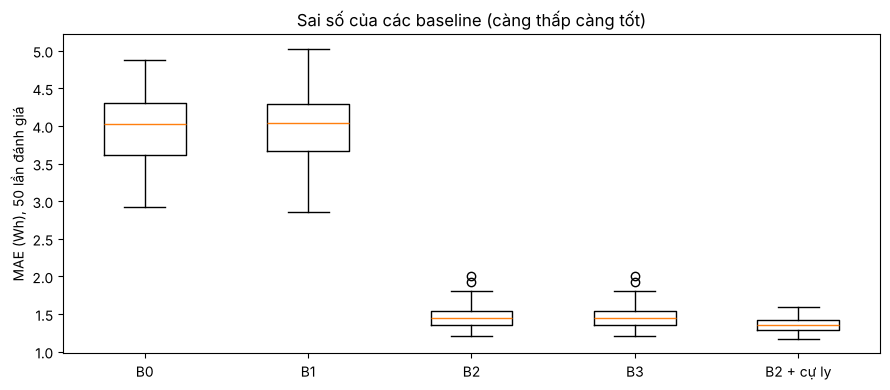

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ten_ngan = ["B0", "B1", "B2", "B3", "B2 + cự ly"]
ax.boxplot([d["MAE"] for d in ket_qua.values()])
ax.set_xticks(range(1, len(ten_ngan) + 1))
ax.set_xticklabels(ten_ngan)
ax.set_ylabel("MAE (Wh), 50 lần đánh giá")
ax.set_title("Sai số của các baseline (càng thấp càng tốt)")
plt.tight_layout()
plt.savefig(FIGURES / "baseline_mae.png", dpi=150)
plt.show()

**Kết luận** (đọc số ở 2 bảng trên):
- **B0 (đoán trung bình)** sai khoảng 4,0 Wh mỗi chuyến (~19% năng lượng trung bình), R² ≈ 0. Đây là mốc "không biết gì".
- **B1 (chỉ cự ly)** gần như không hơn B0. Lý do: 180/192 chuyến cùng route R1, cự ly gần như bằng nhau, nên cự ly một mình không phân biệt được các chuyến.
- **B2 (hồi quy 3 feature)** giảm sai số còn khoảng 1,5 Wh (~7% năng lượng trung bình), R² ≈ 0,83. Chỉ với 3 thông số cài trước khi bay, mô hình đã giải thích được phần lớn khác biệt năng lượng giữa các chuyến.
- **B3 (Ridge)** cho kết quả gần như y hệt B2. Đúng như dự đoán từ notebook 02: 3 feature không tương quan với nhau, nên không có đa cộng tuyến để Ridge phải xử lý → **chọn B2 làm baseline chính** vì đơn giản hơn.

### 4.1 Hệ số hồi quy có ý nghĩa vật lý không?

Fit B2 trên toàn bộ 192 chuyến, tính khoảng tin cậy 95% của từng hệ số. Nếu khoảng tin cậy không chứa 0 thì hệ số có ý nghĩa thống kê.

In [9]:
X = np.column_stack([np.ones(len(df)), df[FEATURE_CHINH]])
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
phan_du = y - X @ beta
n, p = X.shape
s2 = (phan_du ** 2).sum() / (n - p)                 # phương sai của sai số
se = np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X)))  # sai số chuẩn của từng hệ số
t = stats.t.ppf(0.975, n - p)

he_so = pd.DataFrame({
    "hệ số": beta,
    "CI 95% dưới": beta - t * se,
    "CI 95% trên": beta + t * se,
    "p-value": 2 * stats.t.sf(np.abs(beta / se), n - p),
}, index=["hằng số", "speed (mỗi 1 m/s)", "payload (mỗi 1 g)", "altitude (mỗi 1 m)"])
he_so.round(4)

,hệ số,CI 95% dưới,CI 95% trên,p-value
hằng số,21.3249,20.2479,22.4018,0.0
speed (mỗi 1 m/s),-1.0597,-1.1584,-0.9610,0.0
payload (mỗi 1 g),0.0081,0.0067,0.0094,0.0
altitude (mỗi 1 m),0.1048,0.0949,0.1148,0.0


In [10]:
# Đổi ra đơn vị dễ đọc
print(f"Bay nhanh thêm 1 m/s  : {beta[1]:+.2f} Wh")
print(f"Chở thêm 100 g        : {beta[2] * 100:+.2f} Wh")
print(f"Bay cao thêm 25 m     : {beta[3] * 25:+.2f} Wh")

Bay nhanh thêm 1 m/s  : -1.06 Wh
Chở thêm 100 g        : +0.81 Wh
Bay cao thêm 25 m     : +2.62 Wh


**Kết luận:** cả 3 hệ số đều có dấu đúng với vật lý và với EDA, và khoảng tin cậy 95% đều không chứa 0:
- **speed âm:** bay nhanh hơn thì chuyến bay ngắn hơn → tốn ít hơn (notebook 02, mục 3.1).
- **payload dương:** chở nặng thì motor phải gắng hơn → công suất tăng (notebook 02, insight 3).
- **altitude dương:** bay cao thì phải leo và hạ nhiều hơn → tốn hơn, khoảng +2,6 Wh mỗi 25 m, khớp với EDA.

### 4.2 Kiểm tra phần dư (residual)

Phần dư = năng lượng thật − năng lượng mô hình đoán. Dùng dự đoán **out-of-fold** (mỗi chuyến được đoán bởi mô hình chưa thấy nó) để kiểm tra 2 giả định của hồi quy tuyến tính:
1. **Không có khuôn mẫu:** phần dư phải rải đều quanh 0. Nếu có hình cong thì mô hình đang bỏ sót quan hệ cong.
2. **Gần phân phối chuẩn:** kiểm tra bằng Q-Q plot. Các chấm nằm gần đường thẳng là đạt.

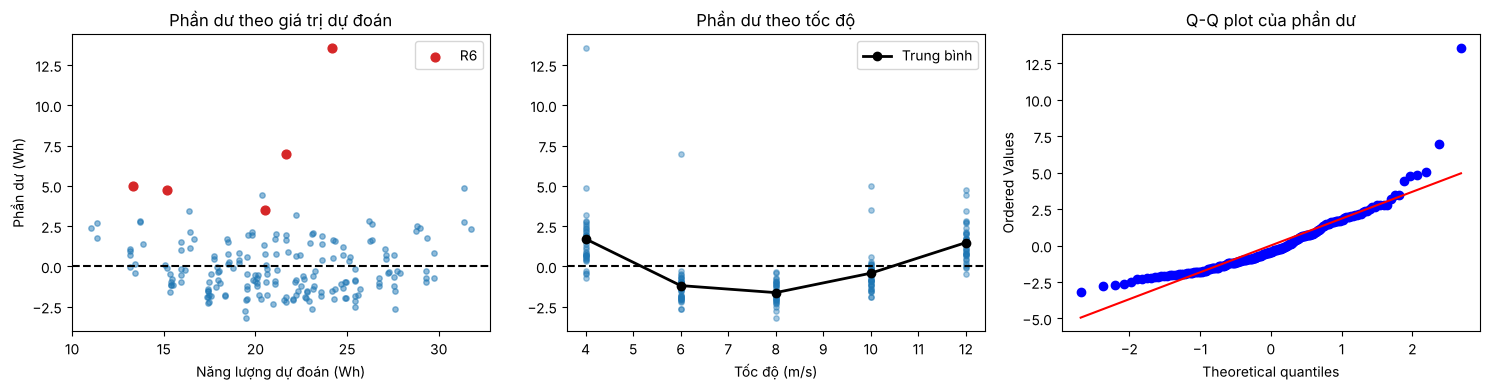

In [11]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
df["du_doan_B2"] = cross_val_predict(LinearRegression(), df[FEATURE_CHINH], y, cv=kf)
df["phan_du_B2"] = y - df["du_doan_B2"]   # dương = đoán THIẾU (thực tế tốn hơn)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].scatter(df["du_doan_B2"], df["phan_du_B2"], alpha=0.5, s=15)
ax[0].axhline(0, color="black", linestyle="--")
r6 = df["route"] == "R6"
ax[0].scatter(df.loc[r6, "du_doan_B2"], df.loc[r6, "phan_du_B2"], color="tab:red", s=40, label="R6")
ax[0].set_xlabel("Năng lượng dự đoán (Wh)")
ax[0].set_ylabel("Phần dư (Wh)")
ax[0].set_title("Phần dư theo giá trị dự đoán")
ax[0].legend()

tb = df.groupby("speed")["phan_du_B2"].mean()
ax[1].scatter(df["speed"], df["phan_du_B2"], alpha=0.4, s=15)
ax[1].plot(tb.index, tb.values, color="black", marker="o", linewidth=2, label="Trung bình")
ax[1].axhline(0, color="black", linestyle="--")
ax[1].set_xlabel("Tốc độ (m/s)")
ax[1].set_title("Phần dư theo tốc độ")
ax[1].legend()

stats.probplot(df["phan_du_B2"], dist="norm", plot=ax[2])
ax[2].set_title("Q-Q plot của phần dư")

plt.tight_layout()
plt.savefig(FIGURES / "baseline_phan_du.png", dpi=150)
plt.show()

In [12]:
print("Phần dư trung bình theo tốc độ (Wh):")
print(df.groupby("speed")["phan_du_B2"].mean().round(2).to_dict())
print("\nPhần dư 5 chuyến R6 (Wh):", df.loc[r6, "phan_du_B2"].round(1).tolist())

Phần dư trung bình theo tốc độ (Wh):
{4.0: 1.7, 6.0: -1.2, 8.0: -1.63, 10.0: -0.42, 12.0: 1.47}

Phần dư 5 chuyến R6 (Wh): [7.0, 4.7, 3.5, 5.0, 13.6]


**Kết luận:**
- **Phần dư theo tốc độ có hình chữ U:** mô hình đoán thiếu ở 4 m/s và 12 m/s, đoán dư ở giữa. Đúng như EDA đã thấy: quan hệ tốc độ – năng lượng là **đường cong**, mà hồi quy tuyến tính chỉ vẽ được đường thẳng. → Mô hình ở notebook 04 cần bắt được đường cong.
- **Q-Q plot:** đoạn giữa nằm sát đường thẳng, lệch ở 2 đuôi, rõ nhất là **đuôi phải** (vài chuyến bị đoán thiếu nhiều, chủ yếu là R6). Giả định phân phối chuẩn chỉ tạm chấp nhận được; khoảng dự đoán ở mục 4.3 vì vậy cần đọc thận trọng.
- **5 chuyến R6 (chấm đỏ) đều bị đoán thiếu.** Đây là loại lỗi nguy hiểm (drone có thể hết pin giữa đường) → xem mục 4.4.

### 4.3 Khoảng dự đoán (prediction interval)

Lập kế hoạch bay cần biết không chỉ "đoán bao nhiêu" mà còn "**có thể tốn tới bao nhiêu**". Khoảng dự đoán 95% cho biết năng lượng thật của một chuyến mới sẽ nằm trong khoảng nào.

In [13]:
def khoang_du_doan(speed, payload, altitude, muc=0.95):
    x0 = np.array([1, speed, payload, altitude])
    du_doan = x0 @ beta
    se_pred = np.sqrt(s2 * (1 + x0 @ np.linalg.inv(X.T @ X) @ x0))
    t = stats.t.ppf((1 + muc) / 2, n - p)
    return du_doan, du_doan - t * se_pred, du_doan + t * se_pred

for vd in [(4, 500, 100), (8, 250, 50), (12, 0, 25)]:
    d, lo, hi = khoang_du_doan(*vd)
    print(f"speed={vd[0]:2d} m/s, payload={vd[1]:3d} g, altitude={vd[2]:3d} m -> đoán {d:5.1f} Wh, khoảng 95%: [{lo:5.1f}, {hi:5.1f}] Wh")

# Kiểm tra: bao nhiêu % chuyến thật nằm trong khoảng 95%?
nua_rong = stats.t.ppf(0.975, n - p) * np.sqrt(s2)
print(f"\nTỉ lệ chuyến nằm trong khoảng ±{nua_rong:.1f} Wh quanh dự đoán out-of-fold: {(df['phan_du_B2'].abs() <= nua_rong).mean():.1%}")

speed= 4 m/s, payload=500 g, altitude=100 m -> đoán  31.6 Wh, khoảng 95%: [ 27.6,  35.5] Wh
speed= 8 m/s, payload=250 g, altitude= 50 m -> đoán  20.1 Wh, khoảng 95%: [ 16.2,  24.0] Wh
speed=12 m/s, payload=  0 g, altitude= 25 m -> đoán  11.2 Wh, khoảng 95%: [  7.3,  15.2] Wh

Tỉ lệ chuyến nằm trong khoảng ±3.9 Wh quanh dự đoán out-of-fold: 96.9%


**Kết luận:**
- Khoảng dự đoán rộng khoảng **±3,9 Wh**. Kiểm tra trên dự đoán out-of-fold: ~97% chuyến thật nằm trong khoảng, sát mức 95% kỳ vọng.
- Muốn an toàn, nên lập kế hoạch pin theo **cận trên** của khoảng chứ không theo số đoán.
- Ví dụ thứ 3 (12 m/s, 0 g, 25 m) đoán 11,2 Wh, thấp hơn mọi chuyến thật (nhỏ nhất 13,0 Wh). Lý do: đường thẳng tiếp tục đi xuống ở 12 m/s, trong khi thực tế năng lượng đã chững lại từ 10 m/s. Lại là dấu hiệu quan hệ cong.

### 4.4 Thí nghiệm thêm: R6 tốn hơn có phải do bay xa hơn?

So B2 (3 feature) với "B2 + cự ly" trên **cùng một cách chia**:

In [14]:
df["du_doan_cu_ly"] = cross_val_predict(LinearRegression(), df[FEATURE_CHINH + ["cu_ly_m"]], y, cv=kf)
df["phan_du_cu_ly"] = y - df["du_doan_cu_ly"]

so_sanh = df.groupby(df["route"].where(df["route"].isin(["R1", "R6"]), "R2–R5"))[["phan_du_B2", "phan_du_cu_ly"]] \
    .agg(lambda s: s.abs().mean()).round(2)
so_sanh.columns = ["MAE 3 feature", "MAE 3 feature + cự ly"]
so_sanh["số chuyến"] = df["route"].where(df["route"].isin(["R1", "R6"]), "R2–R5").value_counts()
so_sanh

,MAE 3 feature,MAE 3 feature + cự ly,số chuyến
route,,,
R1,1.33,1.30,180
R2–R5,1.34,1.46,7
R6,6.76,2.78,5


In [15]:
df.loc[r6, ["flight", "speed", "payload", "altitude", "E_Wh", "phan_du_B2", "phan_du_cu_ly"]].round(1)

,flight,speed,payload,altitude,E_Wh,phan_du_B2,phan_du_cu_ly
184,268,6.0,500.0,25,28.7,7.0,0.3
185,269,12.0,500.0,25,19.9,4.7,-2.4
186,270,10.0,250.0,75,24.0,3.5,-2.7
187,271,10.0,0.0,25,18.4,5.0,-1.0
188,272,4.0,250.0,50,37.7,13.6,7.5


**Kết luận:**
- Với 180 chuyến R1, thêm cự ly **gần như không đổi gì** (các chuyến R1 có cự ly như nhau).
- Với 5 chuyến R6, sai số giảm mạnh: không có cự ly thì cả 5 chuyến bị **đoán thiếu**; có cự ly thì phần lớn về gần 0. Chuyến 272 vẫn còn đoán thiếu nhưng ít hơn nhiều.
- → **R6 tốn hơn chủ yếu vì bay xa hơn** (~836 m so với ~473 m), không phải do lỗi dữ liệu.
- **Hạn chế:** chỉ có 5 chuyến R6 và 6 route, nên bằng chứng còn mỏng. Vì vậy mô hình chính vẫn giữ 3 feature (giống NCKH); cự ly là **hướng mở rộng** khi có thêm dữ liệu nhiều route.

## Ghi chú cho báo cáo

**Bước này tìm ra gì** (dùng cho D3):

1. **Thiết kế đánh giá:** 5-fold × 10 lần lặp (50 lần đánh giá), chia theo chuyến bay, seed 301, mọi mô hình dùng cùng cách chia.
2. **Baseline chính: hồi quy tuyến tính 3 feature** (speed, payload, altitude). MAE ≈ 1,48 Wh (~7% năng lượng trung bình), R² ≈ 0,83, tốt hơn hẳn đoán trung bình (MAE ≈ 4,0 Wh) và chỉ dùng cự ly.
3. **Ridge không cần thiết:** kết quả như hồi quy thường vì 3 feature không tương quan với nhau.
4. **Hệ số hợp lý về vật lý** và đều có ý nghĩa thống kê: nhanh hơn thì tốn ít hơn, nặng hơn và cao hơn thì tốn nhiều hơn.
5. **Điểm yếu của baseline:** (a) phần dư hình chữ U theo tốc độ → bỏ sót quan hệ cong; (b) đoán thiếu cả 5 chuyến R6.
6. **R6:** thêm cự ly route giải thích được phần lớn chênh lệch → R6 tốn hơn vì bay xa hơn.

**Gợi ý cho D4 (notebook 04):** so baseline B2 với mô hình bắt được đường cong (Random Forest / Gradient Boosting), dùng **đúng cách chia ở trên**. Mốc cần vượt: MAE của B2.

**Hình cho báo cáo:** `baseline_mae.png`, `baseline_phan_du.png`. **Bảng:** `reports/baseline_results.csv`.